# Feature-Group Ablation and SHAP Interpretation

This notebook provides the complete interpretability workflow for RQ1. Part A evaluates transaction-behaviour, graph-structural, and combined feature groups. Part B calculates model-specific SHAP attribution for the fitted Random Forest.

Run all cells from a clean kernel. Tables and figures are displayed inline, and only the three core machine-readable CSV artifacts are exported.

## Interpretation scope

Ablation measures predictive differences among feature groups. SHAP describes how the fitted Random Forest distributes attribution on the observed 436-address sample. Correlated predictors can exchange attribution, so individual rankings are interpreted with the M08 correlation-group audit. Primary repeat-level inference remains in `04_supervised/01_traditional_ml/02_repeated_cv.ipynb`.

## Imports and dependencies

In [1]:
from IPython.display import display
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from scipy import stats

## 0. Setup

In [2]:
# Week 9: feature-group ablation (transaction_behaviour vs graph_structural vs
# combined hand-crafted) answers RQ1. SHAP describes how this fitted model
# distributes attribution across individual features and extends the Week 8
# group-contribution diagnostic. Embeddings are excluded because this analysis
# isolates attribution within hand-crafted features; their predictive increment
# is evaluated separately by 04_supervised/01_traditional_ml/02_repeated_cv.ipynb.

RANDOM_STATE = 42
N_SPLITS = 5
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]
MODEL_COLORS = {"LogisticRegression": "#2a78d6", "RandomForest": "#1baf7a", "XGBoost": "#eb6834"}
GROUP_ORDER = ["transaction_behaviour", "graph_structural", "combined"]
GROUP_COLORS = {"transaction_behaviour": "#2a78d6", "graph_structural": "#1baf7a", "combined": "#6b4fa0"}

# Optional CLI args: feat_file edges_file out_subdir.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_cwd, *_cwd.parents]
        if (candidate / "00_data_graph").exists()
        and (candidate / "05_interpretability").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the dissertation workspace.")
FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
FEAT_FILE = FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
OUT_SUBDIR = PROJECT_ROOT / "05_interpretability" / "feature_ablation_shap_results"
FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

OUT_DIR = Path(OUT_SUBDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 10,
})


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()

## 1. Load hand-crafted features + feature groups

In [3]:
feat = pd.read_csv(FEAT_FILE)
with open(FEATURE_GROUPS_FILE) as f:
    feature_groups = json.load(f)

txn_cols = list(feature_groups["transaction_behaviour"])
struct_cols = list(feature_groups["graph_structural"])

## 2. Pagerank rank transform (same as 01_classification.ipynb Section 2)

In [4]:
# Kept identical to the Week 8 script so the "combined" condition here is the
# exact same 28-column hand_crafted feature set already evaluated in Week 8
# (classification_outputs/classification_summary.csv), not a re-derivation
# that could silently drift.

edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
pagerank_rank = pd.Series(nx.pagerank(G)).rank(pct=True)
pagerank_weighted_rank = pd.Series(nx.pagerank(G, weight="tx_count")).rank(pct=True)

feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)

for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
    if col in struct_cols:
        struct_cols.remove(col)
struct_cols += ["pagerank_rank", "pagerank_weighted_rank"]

combined_cols = txn_cols + struct_cols
print(f"transaction_behaviour: {len(txn_cols)} features | graph_structural: {len(struct_cols)} features "
      f"| combined: {len(combined_cols)} features")

transaction_behaviour: 19 features | graph_structural: 9 features | combined: 28 features


## 3. Restrict to active seeds (same 436 as Week 8, embeddings not used here)

In [5]:
data = feat[feat["is_active"]].copy()
print(f"Ablation sample: {len(data)} active labelled seeds")
print(data[LABEL_COL].value_counts().reindex(LABEL_ORDER))

X_txn = data[txn_cols].to_numpy(dtype=float)
X_struct = data[struct_cols].to_numpy(dtype=float)
X_combined = data[combined_cols].to_numpy(dtype=float)
y = data[LABEL_COL].to_numpy()

feature_sets = {"transaction_behaviour": X_txn, "graph_structural": X_struct, "combined": X_combined}

Ablation sample: 436 active labelled seeds
label
CEX               51
DeFi              86
Malicious_MEV    299
Name: count, dtype: int64


## 4. Model builders (identical to 01_classification.ipynb Section 4)

In [6]:
def build_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])


def build_rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)


def build_xgb():
    return XGBClassifier(n_estimators=300, random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)


MODEL_BUILDERS = {"LogisticRegression": build_lr, "RandomForest": build_rf, "XGBoost": build_xgb}
label_encoder = LabelEncoder().fit(LABEL_ORDER)

# Part A: Feature-Group Ablation

## 5. Stratified 5-fold CV for every (feature group, model) combination

In [7]:
# Same random_state as 01_classification.ipynb, so fold membership over these 436
# seeds is identical to Week 8's folds -- the "combined" column here is
# directly paired-comparable against Week 8's hand_crafted results too.

fold_rows = []
for fs_name, X in feature_sets.items():
    for model_name, builder in MODEL_BUILDERS.items():
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
        for fold_i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            model = builder()
            if model_name == "XGBoost":
                y_train_enc = label_encoder.transform(y_train)
                sample_weight = compute_sample_weight("balanced", y_train_enc)
                model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                y_pred = label_encoder.inverse_transform(model.predict(X_test))
            else:
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)

            fold_rows.append({
                "feature_group": fs_name, "model": model_name, "fold": fold_i,
                "macro_f1": f1_score(y_test, y_pred, average="macro"),
                "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
            })
        print(f"Done: {fs_name} / {model_name}")

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(OUT_DIR / "ablation_cv_fold_scores.csv", index=False)

Done: transaction_behaviour / LogisticRegression


Done: transaction_behaviour / RandomForest


Done: transaction_behaviour / XGBoost
Done: graph_structural / LogisticRegression


Done: graph_structural / RandomForest


Done: graph_structural / XGBoost
Done: combined / LogisticRegression


Done: combined / RandomForest


Done: combined / XGBoost


## 6. Summary table

In [8]:
summary = (
    fold_df.groupby(["feature_group", "model"])[["macro_f1", "balanced_accuracy"]]
    .agg(["mean", "std"])
)
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index().round(4)
summary["feature_group"] = pd.Categorical(summary["feature_group"], GROUP_ORDER, ordered=True)
summary["model"] = pd.Categorical(summary["model"], MODEL_ORDER, ordered=True)
summary = summary.sort_values(["feature_group", "model"]).reset_index(drop=True)
# Displayed inline; external export omitted.
print(f"\n=== Feature-group ablation: 5-fold CV summary ===\n{summary.to_string(index=False)}")


=== Feature-group ablation: 5-fold CV summary ===
        feature_group              model  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std
transaction_behaviour LogisticRegression         0.8843        0.0234                  0.8966                 0.0278
transaction_behaviour       RandomForest         0.9221        0.0274                  0.9123                 0.0228
transaction_behaviour            XGBoost         0.9155        0.0079                  0.9057                 0.0116
     graph_structural LogisticRegression         0.6573        0.1016                  0.7337                 0.0858
     graph_structural       RandomForest         0.8350        0.0573                  0.8289                 0.0497
     graph_structural            XGBoost         0.8225        0.0629                  0.8276                 0.0543
             combined LogisticRegression         0.8847        0.0337                  0.8982                 0.0327
             

## 7. Paired tests per model: does adding graph_structural to transaction_behaviour (i.e. combined vs transaction_behaviour alone) actually help, and same for combined vs graph_structural alone?

In [9]:
pair_specs = [("combined", "transaction_behaviour"), ("combined", "graph_structural")]
sig_rows = []
for a_name, b_name in pair_specs:
    for model_name in MODEL_ORDER:
        a = fold_df[(fold_df.feature_group == a_name) & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
        b = fold_df[(fold_df.feature_group == b_name) & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
        diff = a - b
        t_stat, p_val = stats.ttest_rel(a, b)
        sig_rows.append({
            "comparison": f"{a_name} vs {b_name}", "model": model_name,
            "mean_diff": diff.mean(), "paired_t_stat": t_stat, "paired_p_value": p_val,
            "n_folds_improved": int((diff > 0).sum()),
        })

paired_df = pd.DataFrame(sig_rows).round(4)
paired_df.to_csv(OUT_DIR / "ablation_paired_test.csv", index=False)
print(f"\n=== Paired tests (n=5 folds, low power -- indicative only) ===\n{paired_df.to_string(index=False)}")


=== Paired tests (n=5 folds, low power -- indicative only) ===
                       comparison              model  mean_diff  paired_t_stat  paired_p_value  n_folds_improved
combined vs transaction_behaviour LogisticRegression     0.0004         0.0615          0.9539                 2
combined vs transaction_behaviour       RandomForest    -0.0221        -2.0935          0.1044                 0
combined vs transaction_behaviour            XGBoost    -0.0091        -0.8759          0.4305                 1
     combined vs graph_structural LogisticRegression     0.2274         6.4897          0.0029                 5
     combined vs graph_structural       RandomForest     0.0650         4.1830          0.0139                 5
     combined vs graph_structural            XGBoost     0.0840         2.7309          0.0524                 4


## 8. Bar chart: macro-F1 by feature group x model

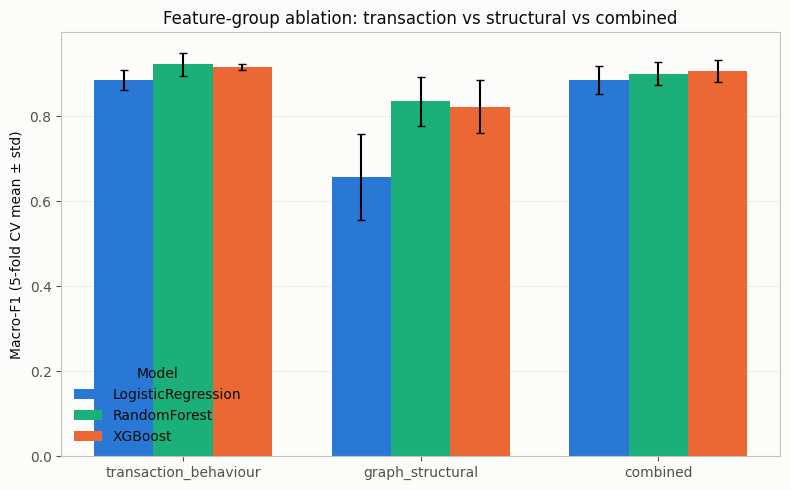

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(GROUP_ORDER))
width = 0.25
for i, model_name in enumerate(MODEL_ORDER):
    sub = summary[summary["model"] == model_name].set_index("feature_group").reindex(GROUP_ORDER)
    ax.bar(x + (i - 1) * width, sub["macro_f1_mean"], width,
           yerr=sub["macro_f1_std"], capsize=3,
           color=MODEL_COLORS[model_name], label=model_name)

ax.set_xticks(x)
ax.set_xticklabels(GROUP_ORDER)
ax.set_ylabel("Macro-F1 (5-fold CV mean ± std)")
ax.set_title("Feature-group ablation: transaction vs structural vs combined")
ax.legend(title="Model", frameon=False)
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

# Part B: SHAP Attribution

## 9. SHAP: how this fitted RF distributes diagnostic attribution across features, and whether the group-level picture agrees with the ablation.


=== Top 10 model-specific mean |SHAP| attributions (RF, all 436 seeds) ===
            feature                 group  mean_abs_shap
weighted_out_degree transaction_behaviour       0.058288
   log_out_tx_count transaction_behaviour       0.052567
       out_tx_count transaction_behaviour       0.050089
   out_gas_fee_mean transaction_behaviour       0.036909
         out_degree      graph_structural       0.033428
     total_tx_count transaction_behaviour       0.032925
 log_total_tx_count transaction_behaviour       0.031988
log_weighted_degree transaction_behaviour       0.030331
    in_gas_fee_mean transaction_behaviour       0.029170
    weighted_degree transaction_behaviour       0.020473

SHAP mass by group: {'graph_structural': 0.1515, 'transaction_behaviour': 0.8485}
(feature-count share: transaction_behaviour=0.679, graph_structural=0.321)


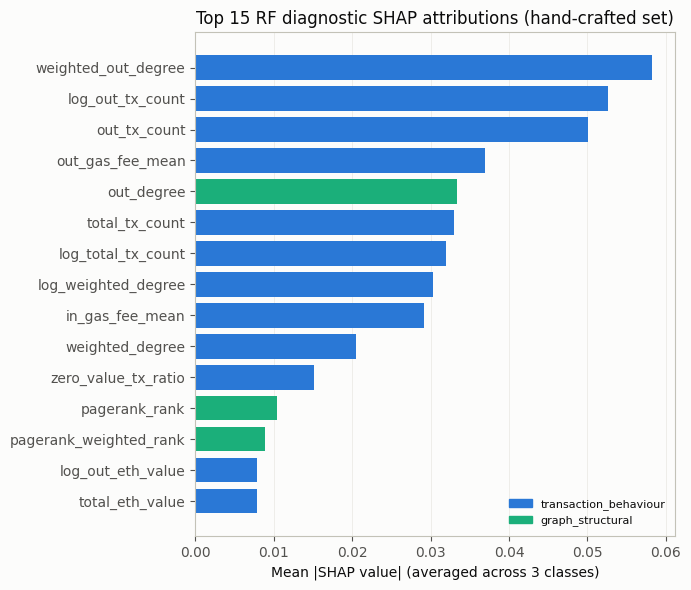


=== Week 9 feature-group ablation + SHAP complete ===


In [11]:
# RF TreeExplainer on the full 436-sample combined (hand_crafted) feature set.
# This is an interpretability diagnostic fit on all available labelled data
# (same convention as 01_classification.ipynb Section 10), not a held-out
# performance or causal claim. Correlated predictors can exchange attribution,
# so individual ranks are interpreted only with the M08 correlation-group
# audit; CV in Sections 5-7 above covers predictive evaluation.

rf_full = build_rf()
rf_full.fit(X_combined, y)

explainer = shap.TreeExplainer(rf_full)
shap_values = explainer.shap_values(X_combined)

# shap>=0.45 TreeExplainer multiclass output is (n_samples, n_features, n_classes)
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3 and shap_values.shape[-1] == len(LABEL_ORDER):
    per_class_mean_abs = np.abs(shap_values).mean(axis=0)  # (n_features, n_classes)
else:
    # older API: list of (n_samples, n_features) arrays, one per class
    per_class_mean_abs = np.stack([np.abs(sv).mean(axis=0) for sv in shap_values], axis=1)

mean_abs_shap_overall = per_class_mean_abs.mean(axis=1)  # averaged across classes

group_lookup = {c: "transaction_behaviour" for c in txn_cols}
group_lookup.update({c: "graph_structural" for c in struct_cols})

shap_summary = pd.DataFrame({
    "feature": combined_cols,
    "group": [group_lookup[c] for c in combined_cols],
    "mean_abs_shap": mean_abs_shap_overall,
})
for i, label in enumerate(LABEL_ORDER):
    shap_summary[f"mean_abs_shap_{label}"] = per_class_mean_abs[:, i]

shap_summary = shap_summary.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_summary.round(5).to_csv(OUT_DIR / "shap_feature_importance.csv", index=False)
print(f"\n=== Top 10 model-specific mean |SHAP| attributions (RF, all 436 seeds) ===")
print(shap_summary.head(10)[["feature", "group", "mean_abs_shap"]].to_string(index=False))

shap_group_mass = shap_summary.groupby("group")["mean_abs_shap"].sum()
shap_group_share = (shap_group_mass / shap_group_mass.sum()).round(4)
print(f"\nSHAP mass by group: {shap_group_share.to_dict()}")
print(f"(feature-count share: transaction_behaviour={len(txn_cols)/len(combined_cols):.3f}, "
      f"graph_structural={len(struct_cols)/len(combined_cols):.3f})")

fig, ax = plt.subplots(figsize=(7, 6))
top_n = 15
top_feats = shap_summary.head(top_n).iloc[::-1]
colors = [GROUP_COLORS[g] for g in top_feats["group"]]
ax.barh(top_feats["feature"], top_feats["mean_abs_shap"], color=colors)
ax.set_xlabel("Mean |SHAP value| (averaged across 3 classes)")
ax.set_title(f"Top {top_n} RF diagnostic SHAP attributions (hand-crafted set)")
ax.grid(axis="x", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER[:2]]
ax.legend(handles, GROUP_ORDER[:2], loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\n=== Week 9 feature-group ablation + SHAP complete ===")

## Core result tables

In [12]:
display(summary)
display(paired_df)
display(shap_summary.head(15))
display(shap_group_share.rename('SHAP attribution share').to_frame())

,feature_group,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,transaction_behaviour,LogisticRegression,0.8843,0.0234,0.8966,0.0278
1,transaction_behaviour,RandomForest,0.9221,0.0274,0.9123,0.0228
2,transaction_behaviour,XGBoost,0.9155,0.0079,0.9057,0.0116
3,graph_structural,LogisticRegression,0.6573,0.1016,0.7337,0.0858
4,graph_structural,RandomForest,0.8350,0.0573,0.8289,0.0497
5,graph_structural,XGBoost,0.8225,0.0629,0.8276,0.0543
6,combined,LogisticRegression,0.8847,0.0337,0.8982,0.0327
7,combined,RandomForest,0.9000,0.0279,0.8884,0.0231
8,combined,XGBoost,0.9065,0.0259,0.9005,0.0296


,comparison,model,mean_diff,paired_t_stat,paired_p_value,n_folds_improved
0,combined vs transaction_behaviour,LogisticRegression,0.0004,0.0615,0.9539,2
1,combined vs transaction_behaviour,RandomForest,-0.0221,-2.0935,0.1044,0
2,combined vs transaction_behaviour,XGBoost,-0.0091,-0.8759,0.4305,1
3,combined vs graph_structural,LogisticRegression,0.2274,6.4897,0.0029,5
4,combined vs graph_structural,RandomForest,0.0650,4.1830,0.0139,5
5,combined vs graph_structural,XGBoost,0.0840,2.7309,0.0524,4


,feature,group,mean_abs_shap,mean_abs_shap_CEX,mean_abs_shap_DeFi,mean_abs_shap_Malicious_MEV
0,weighted_out_degree,transaction_behaviour,0.058288,0.039264,0.063131,0.072471
1,log_out_tx_count,transaction_behaviour,0.052567,0.035234,0.056736,0.065730
2,out_tx_count,transaction_behaviour,0.050089,0.033365,0.055101,0.061800
3,out_gas_fee_mean,transaction_behaviour,0.036909,0.016623,0.048675,0.045429
4,out_degree,graph_structural,0.033428,0.018120,0.048643,0.033520
5,total_tx_count,transaction_behaviour,0.032925,0.034465,0.015236,0.049075
6,log_total_tx_count,transaction_behaviour,0.031988,0.034905,0.013410,0.047650
7,log_weighted_degree,transaction_behaviour,0.030331,0.032814,0.013012,0.045166
8,in_gas_fee_mean,transaction_behaviour,0.029170,0.022661,0.035528,0.029321
9,weighted_degree,transaction_behaviour,0.020473,0.021589,0.009512,0.030320


,SHAP attribution share
group,
graph_structural,0.1515
transaction_behaviour,0.8485


## Thesis-facing interpretation

Transaction-behaviour features carry most of the fitted Random Forest's mean absolute SHAP attribution mass. The ablation results and repeat-level supervised comparisons govern predictive claims. SHAP values remain model-specific descriptive attributions under correlated predictors.